# Sais: nomenclatura e fórmulas
### Funções inorgânicas — sais

**Objetivo:** Nomear sais a partir do ânion, escrever a fórmula balanceando cargas e calcular massa molar e composição percentual.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Nomear um sal é juntar o **nome do ânion** com o **nome do cátion**, na ordem inversa da fórmula:

$$
\underbrace{\mathrm{Na}}_{\text{sódio}} \underbrace{\mathrm{Cl}}_{\text{cloreto}}
\quad\Longrightarrow\quad \text{cloreto de sódio}
$$

A regra de ouro é que o **nome do sal não muda com a quantidade de íons** — $\mathrm{MgCl_2}$ continua sendo "cloreto de magnésio", com prefixos só quando há dúvida.

| Ânion | Sufixo do ânion | Exemplo de sal |
|---|---|---|
| $\mathrm{Cl^-}$ | clor**eto** | NaCl, cloreto de sódio |
| $\mathrm{NO_3^-}$ | nitr**ato** | AgNO₃, nitrato de prata |
| $\mathrm{SO_4^{2-}}$ | sulf**ato** | CuSO₄, sulfato de cobre |
| $\mathrm{CO_3^{2-}}$ | carbon**ato** | CaCO₃, carbonato de cálcio |
| $\mathrm{PO_4^{3-}}$ | fosf**ato** | Ca₃(PO₄)₂, fosfato de cálcio |
| $\mathrm{MnO_4^-}$ | permangan**ato** | KMnO₄, permanganato de potássio |

Para **escrever a fórmula** a partir dos nomes, basta cruzar as cargas:

$$
\boxed{\mathrm{M^{m+}_x\,A^{n-}_y}\ \text{com}\ x\,m = y\,n}
$$

No caso de metais com mais de uma valência (ferro, cobre, chumbo...), o número romano ou o sufixo *-oso*/*-ico* indica qual:

$$
\mathrm{FeCl_2}\ \text{cloreto de ferro II (ferroso)}, \qquad
\mathrm{FeCl_3}\ \text{cloreto de ferro III (férrico)}
$$

## 2. Exemplo resolvido passo a passo

Escrever a fórmula do **fosfato de cálcio**, sabendo que $\mathrm{Ca}$ forma $\mathrm{Ca^{2+}}$ e $\mathrm{PO_4}$ é $\mathrm{PO_4^{3-}}$, e conferir a massa molar.

**Passo 1 — balancear as cargas.** O menor múltiplo comum entre 2 e 3 é 6:

$$
3 \times (+2) = +6 \qquad\text{e}\qquad 2 \times (-3) = -6
$$

**Passo 2 — fórmula.**

$$
\mathrm{Ca_3(PO_4)_2}
$$

**Passo 3 — massa molar.**

$$
M = 3 \cdot 40{,}08 + 2 \cdot (30{,}97 + 4 \cdot 16{,}00) = 120{,}24 + 2 \cdot 94{,}97 = \boxed{310{,}18\ \mathrm{g/mol}}
$$

**Passo 4 — percentual de fósforo** (é o nutriente que interessa no fertilizante):

$$
\%\mathrm{P} = \frac{2 \cdot 30{,}97}{310{,}18} \cdot 100 = \boxed{20{,}0\%}
$$

É por isso que o fosfato de cálcio é a base dos fertilizantes fosfatados e da farinha de ossos.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Fórmula e massa molar a partir dos nomes
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

def descreve(nome, smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido para {nome}: {smiles!r}")
    print(f"{nome:28s} {rdMolDescriptors.CalcMolFormula(mol):14s} "
          f"{Descriptors.MolWt(mol):7.2f} g/mol")

descreve("fosfato de cálcio", "[Ca+2].[Ca+2].[Ca+2].[O-]P(=O)([O-])[O-].[O-]P(=O)([O-])[O-]")
descreve("cloreto de sódio", "[Na+].[Cl-]")
descreve("nitrato de prata", "[Ag+].[O-][N+](=O)[O-]")

# Percentual de fósforo no Ca3(PO4)2
mol = Chem.MolFromSmiles("[Ca+2].[Ca+2].[Ca+2].[O-]P(=O)([O-])[O-].[O-]P(=O)([O-])[O-]")
massa_p = 2 * 30.97
massa_total = Descriptors.MolWt(mol)
print(f"\nmassa molar = {massa_total:.2f} g/mol")
print(f"% de fósforo = {100 * massa_p / massa_total:.1f} %")

fosfato de cálcio            Ca3O8P2         310.17 g/mol
cloreto de sódio             ClNa             58.44 g/mol
nitrato de prata             AgNO3           169.87 g/mol

massa molar = 310.17 g/mol
% de fósforo = 20.0 %


## 4. Visualização

### 4.1 Fosfato de cálcio em 3D — arraste para girar

Três cátions $\mathrm{Ca^{2+}}$ e dois ânions $\mathrm{PO_4^{3-}}$: gire a figura e conte as espécies. É a proporção 3:2 que o balanceamento de cargas previu.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Ca+2].[Ca+2].[Ca+2].[O-]P(=O)([O-])[O-].[O-]P(=O)([O-])[O-]", altura=460)

[16:36:15] UFFTYPER: Unrecognized atom type: Ca+2 (0)
[16:36:15] UFFTYPER: Unrecognized atom type: Ca+2 (0)
[16:36:15] UFFTYPER: Unrecognized atom type: Ca+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Cloreto de ferro(III) em 3D

O $\mathrm{FeCl_3}$ é o "cloreto férrico", usado como coagulante no tratamento de água. Compare com o ferroso ($\mathrm{FeCl_2}$): muda um cloreto e a cor/aplicação mudam bastante.

In [4]:
molecula_3d("[Fe+3].[Cl-].[Cl-].[Cl-]")

[16:36:15] UFFTYPER: Unrecognized atom type: Fe2+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

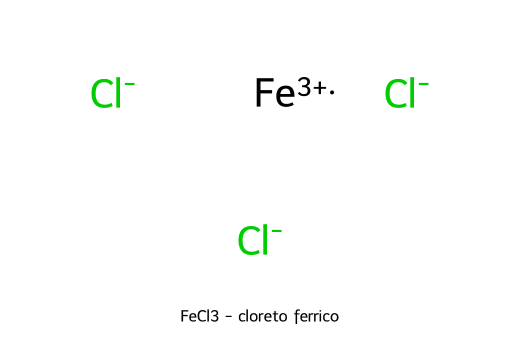

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Ca+2].[Ca+2].[Ca+2].[O-]P(=O)([O-])[O-].[O-]P(=O)([O-])[O-]", legenda="Ca3(PO4)2 - fosfato de calcio", altura=420)
estrutura_2d("[Fe+3].[Cl-].[Cl-].[Cl-]", legenda="FeCl3 - cloreto ferrico")

### 4.4 Galeria: ânion → sal

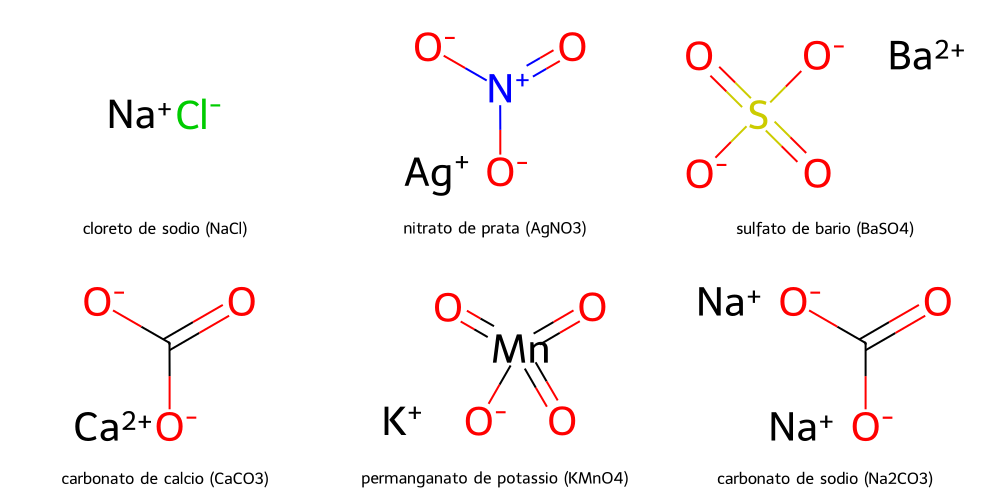

In [6]:
# @title Nomes e fórmulas
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

pares = [
    ("cloreto de sodio (NaCl)", "[Na+].[Cl-]"),
    ("nitrato de prata (AgNO3)", "[Ag+].[O-][N+](=O)[O-]"),
    ("sulfato de bario (BaSO4)", "[Ba+2].[O-]S(=O)(=O)[O-]"),
    ("carbonato de calcio (CaCO3)", "[Ca+2].[O-]C(=O)[O-]"),
    ("permanganato de potassio (KMnO4)", "[K+].[O-][Mn](=O)(=O)=O"),
    ("carbonato de sodio (Na2CO3)", "[Na+].[Na+].[O-]C(=O)[O-]"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in pares],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in pares], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 Composição percentual de um sal

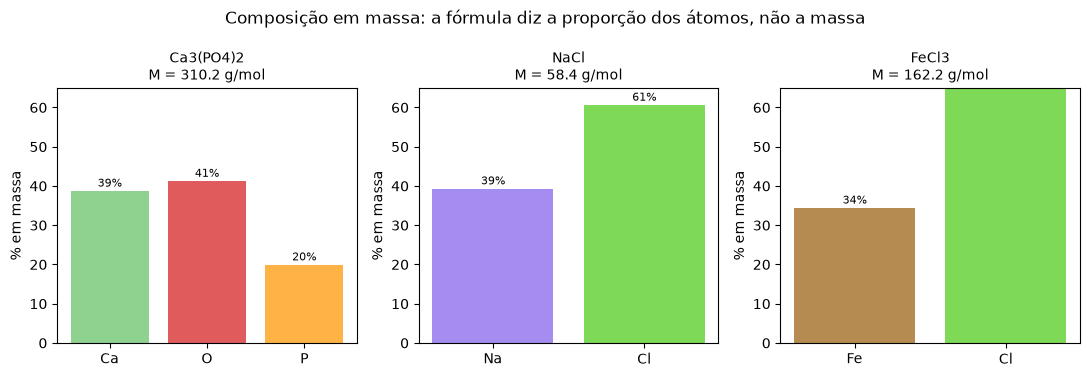

In [7]:
# @title Percentual de cada elemento
import matplotlib.pyplot as plt
from collections import Counter
from rdkit.Chem import Descriptors

massa_atomica = {"Ca": 40.08, "P": 30.97, "O": 16.00, "Na": 22.99, "Cl": 35.45,
                 "Fe": 55.85, "S": 32.06, "K": 39.10, "Mn": 54.94, "N": 14.01}

def composicao(smiles):
    mol = Chem.MolFromSmiles(smiles)
    contagem = Counter(atom.GetSymbol() for atom in mol.GetAtoms())
    total = sum(massa_atomica[el] * n for el, n in contagem.items())
    return {el: 100 * massa_atomica[el] * n / total for el, n in contagem.items()}, total

dados = {
    "Ca3(PO4)2": "[Ca+2].[Ca+2].[Ca+2].[O-]P(=O)([O-])[O-].[O-]P(=O)([O-])[O-]",
    "NaCl": "[Na+].[Cl-]",
    "FeCl3": "[Fe+3].[Cl-].[Cl-].[Cl-]",
}

figura, eixos = plt.subplots(1, 3, figsize=(11, 3.8))
cores = {"Ca": "#8fd18f", "P": "#ffb347", "O": "#e05c5c", "Na": "#a48cf0",
         "Cl": "#7ed957", "Fe": "#b58b52"}
for eixo, (nome, smiles) in zip(eixos, dados.items()):
    fracao, total = composicao(smiles)
    rotulos = list(fracao)
    eixo.bar(rotulos, [fracao[r] for r in rotulos], color=[cores.get(r, "#999") for r in rotulos])
    eixo.set_title(f"{nome}\nM = {total:.1f} g/mol", fontsize=10)
    eixo.set_ylabel("% em massa")
    eixo.set_ylim(0, 65)
    for i, r in enumerate(rotulos):
        eixo.annotate(f"{fracao[r]:.0f}%", (i, fracao[r]), xytext=(0, 3),
                      textcoords="offset points", ha="center", fontsize=8)
figura.suptitle("Composição em massa: a fórmula diz a proporção dos átomos, não a massa")
figura.tight_layout()
plt.show()

### 4.6 O mesmo ânion, metais diferentes

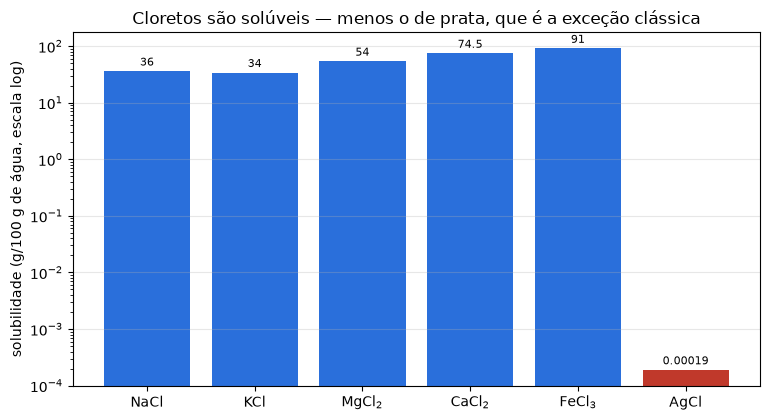

In [8]:
# @title Solubilidade dos cloretos
metais = ["NaCl", "KCl", "MgCl$_2$", "CaCl$_2$", "FeCl$_3$", "AgCl"]
solubilidade = [36.0, 34.0, 54.0, 74.5, 91.0, 0.00019]

plt.figure(figsize=(7.8, 4.3))
cores_barras = ["#2a6fdb"] * 5 + ["#c0392b"]
plt.bar(metais, solubilidade, color=cores_barras, log=True)
for i, valor in enumerate(solubilidade):
    plt.annotate(f"{valor:g}", (i, valor), xytext=(0, 4), textcoords="offset points",
                 ha="center", fontsize=8)
plt.ylabel("solubilidade (g/100 g de água, escala log)")
plt.title("Cloretos são solúveis — menos o de prata, que é a exceção clássica")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- O nome do sal é "ânion de cátion". Trocar o metal muda o nome do cátion, não o do ânion.
- A fórmula é o balanceamento de carga: o número de cargas positivas tem que igualar o de negativas.
- Metais com mais de uma valência precisam de número romano (ou sufixo -oso/-ico) para não haver ambiguidade.
- A composição percentual é diferente da proporção atômica: no $\mathrm{Ca_3(PO_4)_2}$ o oxigênio é a maior fração em massa (41%), apesar de o fósforo ser o "nutriente" que interessa.
- Solubilidade é propriedade do **par** cátion+ânion, não de cada íon isolado.

## 6. Exercício de fixação

Escreva a fórmula e calcule a massa molar do **sulfato de alumínio**, sabendo que $\mathrm{Al}$ forma $\mathrm{Al^{3+}}$ e o sulfato é $\mathrm{SO_4^{2-}}$.

In [9]:
# @title Exercício
smiles_ex = "[Al+3].[Al+3].[O-]S(=O)(=O)[O-].[O-]S(=O)(=O)[O-].[O-]S(=O)(=O)[O-]"
mol_ex = Chem.MolFromSmiles(smiles_ex)
print(f"sulfato de alumínio: Al2(SO4)3")
print(f"fórmula (Hill):      {rdMolDescriptors.CalcMolFormula(mol_ex)}  (Al2O12S3 = Al2(SO4)3)")
print(f"massa molar:         {Descriptors.MolWt(mol_ex):.2f} g/mol")
print(f"balanceamento: 2 x (+3) = +6  e  3 x (-2) = -6")

sulfato de alumínio: Al2(SO4)3
fórmula (Hill):      Al2O12S3  (Al2O12S3 = Al2(SO4)3)
massa molar:         342.15 g/mol
balanceamento: 2 x (+3) = +6  e  3 x (-2) = -6


## 7. Resumo

- Nome do sal: ânion + "de" + cátion.
- Sufixos dos ânions: -eto, -ato, -ito.
- Fórmula: $x\,m = y\,n$ (cargas se cancelam).
- Metais de valência variável usam número romano: ferro II/III, cobre I/II.
- Massa molar = soma das massas atômicas; composição % é fração em massa.

## Referências

- IUPAC. *Nomenclature of Inorganic Chemistry* (Red Book).
- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.